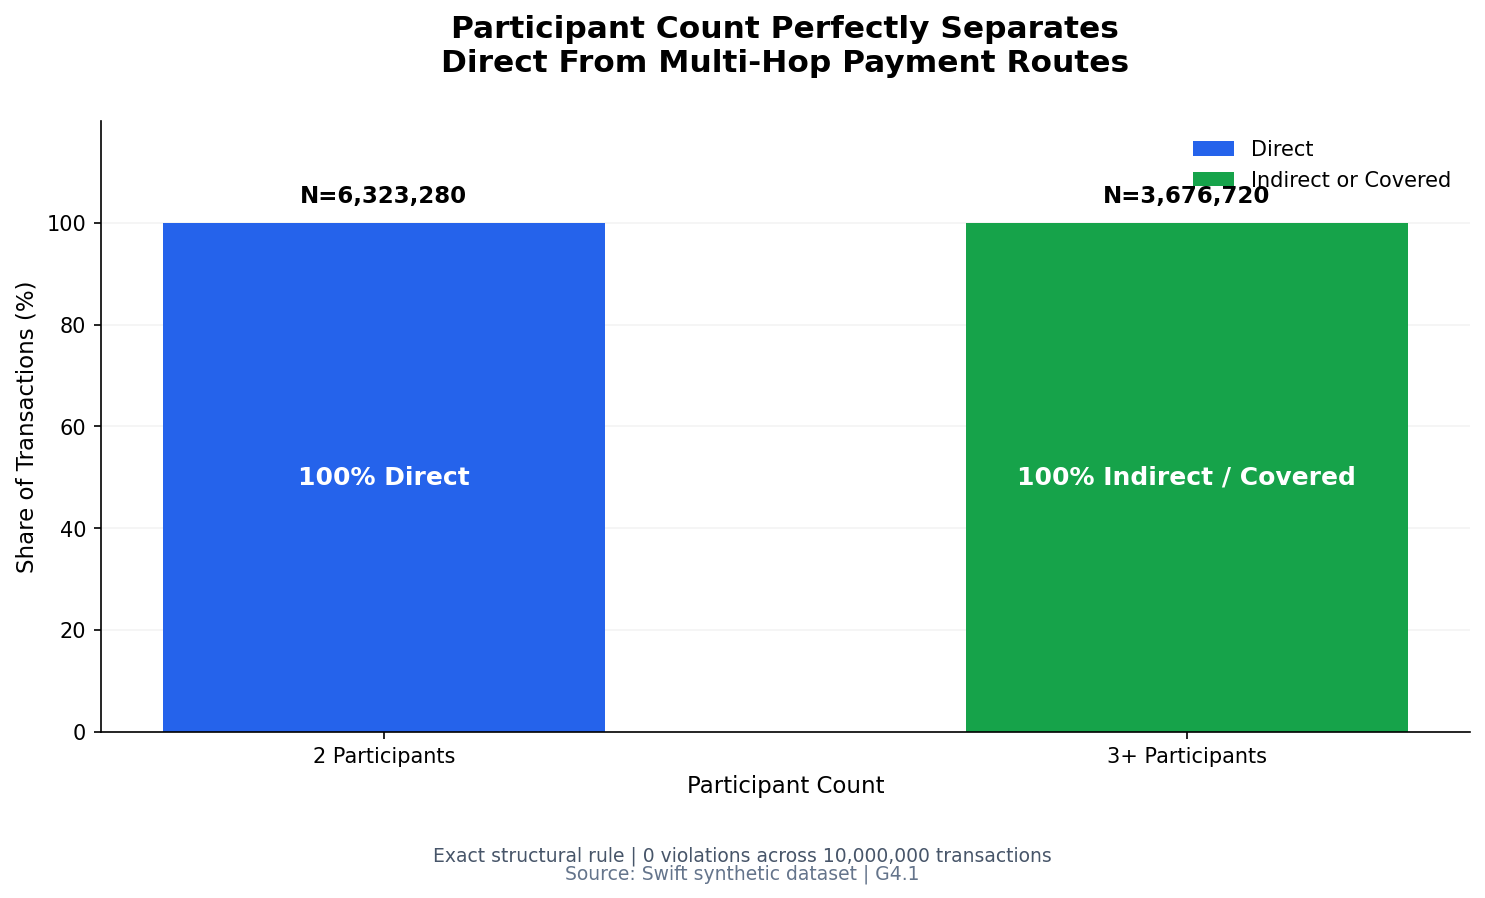

In [2]:

import matplotlib.pyplot as plt

# Verified data from Person 2, Rule G4.1
# Total: 10,000,000 transactions

categories = [
    "2 Participants",
    "3+ Participants"
]

direct_counts = [6323280, 0]
multihop_counts = [0, 3676720]

total_counts = [
    direct_counts[i] + multihop_counts[i]
    for i in range(2)
]

direct_rates = [
    direct_counts[i] / total_counts[i] * 100
    for i in range(2)
]

multihop_rates = [
    multihop_counts[i] / total_counts[i] * 100
    for i in range(2)
]

# Create stacked percentage chart
fig, ax = plt.subplots(figsize=(10, 6), dpi=150)

ax.bar(
    categories,
    direct_rates,
    color="#2563EB",
    label="Direct",
    width=0.55
)

ax.bar(
    categories,
    multihop_rates,
    bottom=direct_rates,
    color="#16A34A",
    label="Indirect or Covered",
    width=0.55
)

# Add labels
for i, category in enumerate(categories):
    label = (
        "100% Direct"
        if i == 0
        else "100% Indirect / Covered"
    )

    ax.text(
        i, 50,
        label,
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white"
    )

    ax.text(
        i, 104,
        f"N={total_counts[i]:,}",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.set_title(
    "Participant Count Perfectly Separates\n"
    "Direct From Multi-Hop Payment Routes",
    fontsize=15,
    fontweight="bold",
    pad=24
)

ax.set_ylabel("Share of Transactions (%)", fontsize=11)
ax.set_xlabel("Participant Count", fontsize=11)

ax.set_ylim(0, 120)
ax.set_yticks([0, 20, 40, 60, 80, 100])

ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    loc="upper right",
    frameon=False
)

fig.text(
    0.5, 0.035,
    "Exact structural rule | "
    "0 violations across 10,000,000 transactions",
    ha="center",
    fontsize=9,
    color="#475569"
)

fig.text(
    0.5, 0.015,
    "Source: Swift synthetic dataset | "
    "G4.1",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.08, 1, 1])

plt.savefig(
    "g4_participants_and_route.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
